Step 0: Load and validate

In [1]:

# ------------------------------------------------------------
# STEP 0: Load the dataset and check what we have
# ------------------------------------------------------------

# pandas: working with tables (dataframes)
import pandas as pd

# matplotlib and seaborn: drawing charts
import matplotlib.pyplot as plt
import seaborn as sns

# Name of your CSV file. It must be in the same folder as this notebook.
# Copy the exact name from File Explorer (turn on View > Show > File name extensions).
file_name = "Womens Clothing E-Commerce Reviews.csv"

# Read the CSV file into a table called df ("data frame")
df = pd.read_csv(file_name)


In [2]:
# Show every column in previews instead of hiding the middle ones with "..."
pd.set_option("display.max_columns", None)

# Number of rows and columns
print("Shape:", df.shape)

# Column names, data types and how many values are filled in
df.info()

# Missing values in each column
print("\nMissing values per column:\n", df.isnull().sum())

# Fully duplicated rows
print("\nDuplicate rows:", df.duplicated().sum())

# First 5 rows
df.head()

Shape: (23486, 11)
<class 'pandas.DataFrame'>
RangeIndex: 23486 entries, 0 to 23485
Data columns (total 11 columns):
 #   Column                   Non-Null Count  Dtype
---  ------                   --------------  -----
 0   Unnamed: 0               23486 non-null  int64
 1   Clothing ID              23486 non-null  int64
 2   Age                      23486 non-null  int64
 3   Title                    19676 non-null  str  
 4   Review Text              22641 non-null  str  
 5   Rating                   23486 non-null  int64
 6   Recommended IND          23486 non-null  int64
 7   Positive Feedback Count  23486 non-null  int64
 8   Division Name            23472 non-null  str  
 9   Department Name          23472 non-null  str  
 10  Class Name               23472 non-null  str  
dtypes: int64(6), str(5)
memory usage: 9.5 MB

Missing values per column:
 Unnamed: 0                    0
Clothing ID                   0
Age                           0
Title                      3810
Revi

,Unnamed: 0,Clothing ID,Age,Title,Review Text,Rating,Recommended IND,Positive Feedback Count,Division Name,Department Name,Class Name
0,0,767,33,NaN,Absolutely wonderful - silky and sexy and comf...,4,1,0,Initmates,Intimate,Intimates
1,1,1080,34,NaN,Love this dress! it's sooo pretty. i happene...,5,1,4,General,Dresses,Dresses
2,2,1077,60,Some major design flaws,I had such high hopes for this dress and reall...,3,0,0,General,Dresses,Dresses
3,3,1049,50,My favorite buy!,"I love, love, love this jumpsuit. it's fun, fl...",5,1,0,General Petite,Bottoms,Pants
4,4,847,47,Flattering shirt,This shirt is very flattering to all due to th...,5,1,6,General,Tops,Blouses


Step 1: Clean the data and create the sentiment label

Dropped the row-number column and 845 reviews with no text (22,641 remain), filled missing titles, joined title and review into one text field, and created the label from the rating (1-2 Negative, 3 Neutral, 4-5 Positive).
**Finding:** 77.1% Positive, 12.5% Neutral, 10.5% Negative. The classes are imbalanced, so accuracy alone is misleading.

In [3]:
# Drop the extra row-number column (it has no information)
df = df.drop(columns=["Unnamed: 0"])

# Remove reviews that have no text
df = df.dropna(subset=["Review Text"])

# Many reviews have no title. Replace the missing titles with a blank
df["Title"] = df["Title"].fillna("")

# Join the title and the review into one text column
df["Full_Text"] = df["Title"] + " " + df["Review Text"]

# Turn the star rating into a sentiment label
# 1-2 stars = Negative, 3 stars = Neutral, 4-5 stars = Positive
def rating_to_sentiment(rating):
    if rating <= 2:
        return "Negative"
    elif rating == 3:
        return "Neutral"
    else:
        return "Positive"

df["Sentiment"] = df["Rating"].apply(rating_to_sentiment)

# Renumber the rows 0, 1, 2... after removing some
df = df.reset_index(drop=True)

# Check the result. Expected shape: about (22641, 11)
print("Shape after cleaning:", df.shape)

# How many reviews per sentiment, and the percentage
print(df["Sentiment"].value_counts())
print((df["Sentiment"].value_counts(normalize=True) * 100).round(1))

Shape after cleaning: (22641, 12)
Sentiment
Positive    17448
Neutral      2823
Negative     2370
Name: count, dtype: int64
Sentiment
Positive    77.1
Neutral     12.5
Negative    10.5
Name: proportion, dtype: float64


Step 2: Sentiment chart and review length

**Finding:** Positive reviews dominate (77.1%), so the classes are imbalanced. Review length is similar across sentiments (about 60 words on average), so length does not separate them. The text itself has to carry the signal.

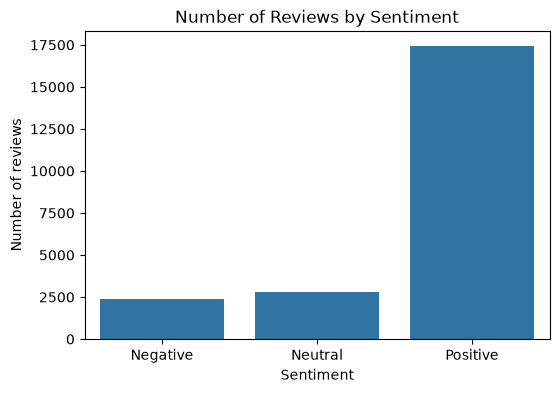

Sentiment
Negative    60.9
Neutral     64.2
Positive    59.5
Name: Word_Count, dtype: float64


In [4]:
# Bar chart: number of reviews for each sentiment
plt.figure(figsize=(6, 4))
sns.countplot(x="Sentiment", data=df, order=["Negative", "Neutral", "Positive"])
plt.title("Number of Reviews by Sentiment")
plt.xlabel("Sentiment")
plt.ylabel("Number of reviews")
plt.show()

# Count the words in each review
df["Word_Count"] = df["Review Text"].str.split().str.len()

# Average review length for each sentiment
print(df.groupby("Sentiment")["Word_Count"].mean().round(1))

Step 3: Turn the text into numbers and split the data

Used the review text (title plus review) as input and the sentiment as target, with the rating excluded from the inputs because the label was made from it. Split 80/20 with stratification (18,112 train / 4,529 test). Converted text to TF-IDF features using single words and word pairs (20,000 features), fitted on the training reviews only to avoid data leakage.

In [5]:
# Tools for splitting the data and turning text into numbers
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer

# X = the text the model reads. y = the sentiment it must predict.
# We do NOT use the Rating as an input, because the label was made from it (that would give away the answer).
X = df["Full_Text"]
y = df["Sentiment"]

# Split: 80% to teach the model, 20% to test it
# stratify=y keeps the same Positive/Neutral/Negative shares in both parts
# random_state=42 makes the split the same every time
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

# TF-IDF turns each review into numbers: a word scores high if it is frequent in that review
# but rare across all reviews.
# lowercase: treats "Love" and "love" as the same word
# ngram_range=(1, 2): uses single words AND word pairs, so "not good" is kept as its own clue
# min_df=5: ignores words that appear in fewer than 5 reviews (mostly typos)
# max_features=20000: keeps the 20,000 most useful words and pairs
tfidf = TfidfVectorizer(lowercase=True, ngram_range=(1, 2), min_df=5, max_features=20000)

# Learn the vocabulary from the TRAINING reviews only, then convert them
X_train_tfidf = tfidf.fit_transform(X_train)

# Convert the test reviews with the same vocabulary (the test data must stay unseen)
X_test_tfidf = tfidf.transform(X_test)

# Check the sizes: expected about 18,112 training reviews and 4,529 test reviews
print("Train:", X_train_tfidf.shape, "| Test:", X_test_tfidf.shape)

Train: (18112, 20000) | Test: (4529, 20000)


Step 4: Train the model and check the results

Trained on TF-IDF features with balanced class weights.
**Findings:** Accuracy 0.815 (vs 0.771 for always predicting Positive), macro F1 0.65. Positive reviews are predicted well (F1 0.92). Negative reviews are moderate (recall 0.63, precision 0.54). Neutral is weakest (F1 0.45), because 3-star reviews mix positive and negative language.
**Note:** Because the classes are imbalanced, per-class recall and F1 are more informative than accuracy.

In [6]:
# Logistic Regression and the scoring tools
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, accuracy_score

# class_weight="balanced" makes the rarer groups (Negative, Neutral) count more
# max_iter=1000 gives the model enough steps to finish learning
model = LogisticRegression(max_iter=1000, class_weight="balanced", random_state=42)

# Teach the model using the TRAINING data only
model.fit(X_train_tfidf, y_train)

# Predict the sentiment of the test reviews
pred = model.predict(X_test_tfidf)

# Overall accuracy. Compare it with 0.771, the score of always guessing "Positive".
print("Accuracy:", round(accuracy_score(y_test, pred), 3))

# Precision, recall and F1 for each sentiment
print(classification_report(y_test, pred))

Accuracy: 0.815
              precision    recall  f1-score   support

    Negative       0.54      0.63      0.58       474
     Neutral       0.39      0.52      0.45       565
    Positive       0.96      0.89      0.92      3490

    accuracy                           0.81      4529
   macro avg       0.63      0.68      0.65      4529
weighted avg       0.85      0.81      0.83      4529



Step 5: Confusion matrix

**Findings:** The model correctly classified 3,690 of 4,529 test reviews. Mistakes are mostly between neighbouring classes: 305 Positive reviews were predicted Neutral, and 161 Negative and 167 Neutral reviews were mixed up. Only 104 reviews (about 2.3%) were flipped between Positive and Negative.
**Interpretation:** Neutral (3-star) reviews mix positive and negative language, so they are the hardest to separate. The model separates clearly happy from clearly unhappy customers much better than it handles the middle.

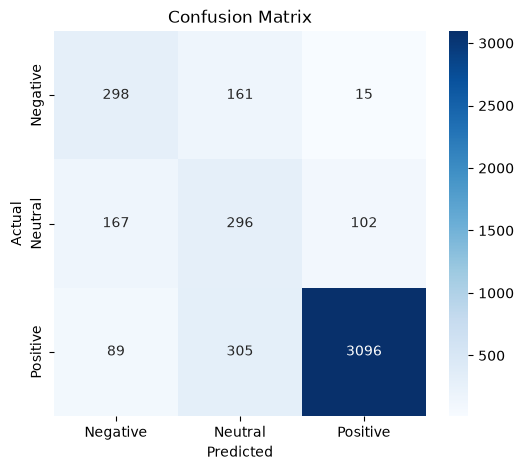

In [7]:
from sklearn.metrics import confusion_matrix

# The order of the labels in the chart
labels = ["Negative", "Neutral", "Positive"]

# Count what the model got right and wrong
# Rows = what really happened, columns = what the model predicted
cm = confusion_matrix(y_test, pred, labels=labels)

# Draw it as a heatmap with the counts inside each box
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=labels, yticklabels=labels)
plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

Step 6: Which words signal each sentiment?

**Findings:** Negative reviews are marked by words about disappointment (disappointed, horrible, awful), fit (unflattering, huge) and quality (poor, cheap), plus return language ("going back", "returning it"). Positive reviews are marked by love, perfect, great, comfortable, soft and flattering. Neutral reviews are marked by contrast words (however, but, unfortunately) and "just ok" or "meh", which explains why Neutral is the hardest class to predict.
**Caution:** Some top words are generic (with, was, even), and the weights show association, not cause.


Top words for Negative:
['disappointed', 'not', 'horrible', 'unflattering', 'poor', 'huge', 'awful', 'disappointing', 'cheap', 'terrible', 'looked', 'even', 'going back', 'was', 'wanted']

Top words for Neutral:
['however', 'not for', 'but', 'ok', 'to love', 'however the', 'returning it', 'just ok', 'if', 'color and', 'unfortunately', 'meh', 'is cute', 'like the', 'much']

Top words for Positive:
['love', 'perfect', 'great', 'comfortable', 'not too', 'little', 'comfy', 'love this', 'perfectly', 'unique', 'beautiful', 'flattering', 'soft', 'fits', 'with']


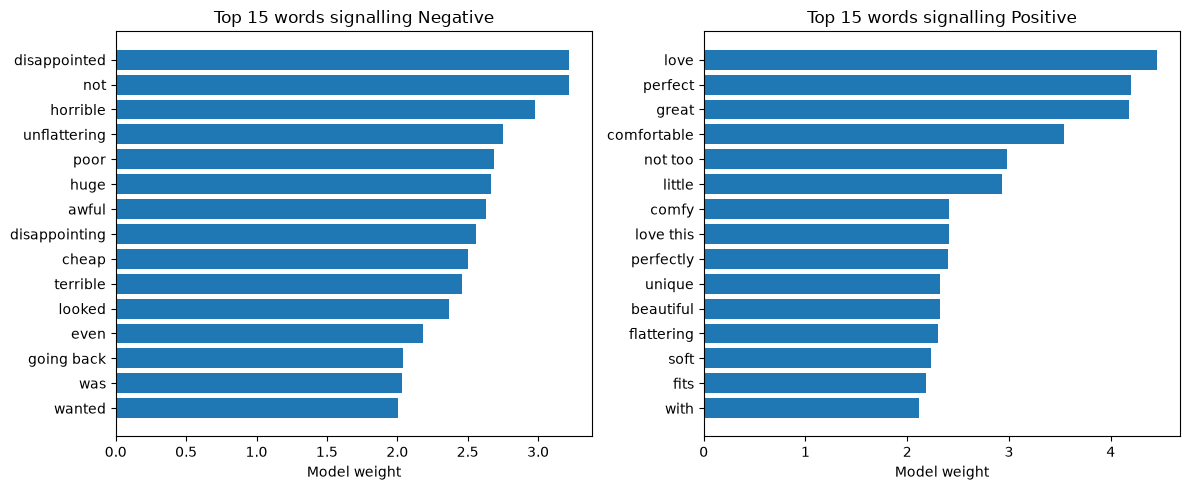

In [8]:
# The list of all 20,000 words and word pairs the model knows
feature_names = tfidf.get_feature_names_out()

# model.classes_ is the order of the classes: Negative, Neutral, Positive
for i, sentiment in enumerate(model.classes_):
    # model.coef_[i] holds one weight per word for this class.
    # argsort() orders the words from lowest to highest weight. We take the last 15 (the highest).
    top_idx = model.coef_[i].argsort()[-15:][::-1]
    # Print the 15 words that push a review most strongly toward this sentiment
    print(f"\nTop words for {sentiment}:")
    print([feature_names[j] for j in top_idx])

# Bar charts for Negative and Positive
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, sentiment in zip(axes, ["Negative", "Positive"]):
    # Find this class's row in the weight table
    i = list(model.classes_).index(sentiment)
    top_idx = model.coef_[i].argsort()[-15:]
    # Horizontal bars: longer bar = stronger signal
    ax.barh([feature_names[j] for j in top_idx], model.coef_[i][top_idx])
    ax.set_title(f"Top 15 words signalling {sentiment}")
    ax.set_xlabel("Model weight")

plt.tight_layout()
plt.show()

Step 7: Testing the model on new reviews

**Finding:** The model labelled the clearly positive review Positive, the clearly negative review Negative, and the mixed review ("okay, however...") Neutral, using the same contrast words it learned in Step 6.
**Caution:** Three hand-written examples are only a demo. The real evaluation is the test-set results in Steps 4 and 5.

In [9]:
# Some made-up reviews to test the model on
new_reviews = [
    "Love this dress, so comfortable and the fabric is soft",
    "Terrible quality, the fabric feels cheap and it was huge on me",
    "It is okay, however the color is different from the photo",
]

# Turn the new reviews into numbers using the SAME TF-IDF vocabulary
new_tfidf = tfidf.transform(new_reviews)

# Predict the sentiment of each one
predictions = model.predict(new_tfidf)

# Print each review with its predicted sentiment
for review, label in zip(new_reviews, predictions):
    print(f"{label:9} | {review}")

Positive  | Love this dress, so comfortable and the fabric is soft
Negative  | Terrible quality, the fabric feels cheap and it was huge on me
Neutral   | It is okay, however the color is different from the photo


## Step 8: Business recommendations
1. **Fix fit and sizing information.** Complaints use words such as "huge" and "unflattering". Add clearer size guides, measurements and fit notes on product pages.
2. **Check fabric quality on the worst-rated items.** Words such as "poor" and "cheap" point to quality complaints. Review the products behind them.
3. **Watch return language.** "Going back" and "returning it" mark unhappy customers, so track these reviews for returns and service follow-up.
4. **Use the model to find unhappy customers fast.** It catches about 63% of negative reviews. Route those to customer care first.
5. **Treat Neutral reviews as a signal.** Words like "however" and "unfortunately" show customers who like the product but have one specific problem, which is useful feedback for product teams.

## Summary
- 22,641 reviews analysed; 77.1% Positive, 12.5% Neutral, 10.5% Negative.
- Logistic Regression on TF-IDF features: accuracy 0.815 (vs 0.771 baseline), macro F1 0.65.
- Positive is predicted well (F1 0.92), Negative moderately (F1 0.58), Neutral weakest (F1 0.45).
- Only about 2.3% of test reviews were flipped between Positive and Negative; most errors involve Neutral.

## Limitations
- Labels come from star ratings, which are an imperfect proxy for the feeling in the text.
- Neutral (3-star) reviews mix positive and negative language.
- Single train/test split; cross-validation would give a steadier estimate.
- Data covers women's clothing reviews from one platform.

## Next steps
Try a VADER or transformer baseline, tune the model, and use cross-validation.